IMPORTING LIBRARIES

In [1]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline


LOADING DATA

`raw` is never modified in this notebook. Every fix is only *diagnosed* here; the real cleaning is written in `src/data_cleaning.py`.

In [2]:
raw = pd.read_csv("../data/raw.csv")

BASIC ANALYSIS OF DATA

Columns in Dataset

In [3]:
raw.columns

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='str')

Shape of Dataset

In [4]:
raw.shape

(15411, 14)

Few Records from Dataset

In [5]:
raw.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


Datatypes of columns of dataset:

In [6]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  str    
 2   brand              15411 non-null  str    
 3   model              15411 non-null  str    
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  str    
 7   fuel_type          15411 non-null  str    
 8   transmission_type  15411 non-null  str    
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), str(6)
memory usage: 1.6 MB


Statistical Info of Dataset

In [7]:
raw.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,15411.0,9811.9,5643.4,0.0,4906.5,9872.0,14668.5,19543.0
vehicle_age,15411.0,6.0,3.0,0.0,4.0,6.0,8.0,29.0
km_driven,15411.0,55616.5,51618.5,100.0,30000.0,50000.0,70000.0,3800000.0
mileage,15411.0,19.7,4.2,4.0,17.0,19.7,22.7,33.5
engine,15411.0,1486.1,521.1,793.0,1197.0,1248.0,1582.0,6592.0
max_power,15411.0,100.6,43.0,38.4,74.0,88.5,117.3,626.0
seats,15411.0,5.3,0.8,0.0,5.0,5.0,5.0,9.0
selling_price,15411.0,774971.1,894128.4,40000.0,385000.0,556000.0,825000.0,39500000.0


COUNTING NULL VALUES

In [8]:
raw.isnull().sum()

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

Number of unique values in each column

In [9]:
raw.nunique()

Unnamed: 0           15411
car_name               121
brand                   32
model                  120
vehicle_age             24
km_driven             3688
seller_type              3
fuel_type                5
transmission_type        2
mileage                411
engine                 110
max_power              342
seats                    8
selling_price         1086
dtype: int64

'Unnamed: 0' is just the index (one unique value per row) and carries no information.

DATA QUALITY 

In [10]:
df = raw.loc[:, ~raw.columns.str.startswith("Unnamed")].copy()
print(df.shape)

(15411, 13)


Counting Duplicates

In [43]:
full_dups = df.duplicated().sum()
print(f"Exact duplicate rows (price included) : {full_dups}")

Exact duplicate rows (price included) : 167


In [42]:
features = [c for c in df.columns if c != "selling_price"]

# rows that share features with at least one other row
shared = df.duplicated(subset=features, keep=False)

# among those, groups that have more than one distinct price
n_prices = df.groupby(features)["selling_price"].transform("nunique")
conflict = shared & (n_prices > 1)

print(conflict.sum(), f"{conflict.mean():.1%}")

2257 14.6%


2257 rows (14.6%) have exactly the same recorded details as at least one other car, but sold for different prices.

Redundant Columns

In [12]:
mismatch = (df["car_name"] != df["brand"] + " " + df["model"]).sum()
print(f"Rows where car_name != brand + model: {mismatch}")

Rows where car_name != brand + model: 0


Text Consistency

In [13]:
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
cleaned_cols = df[text_cols].apply(lambda s: s.str.strip().str.lower())
comparison = pd.DataFrame({"raw_unique": df[text_cols].nunique(),
                           "cleaned_unique": cleaned_cols.nunique()})
comparison["merged_by_cleaning"] = comparison["raw_unique"] - comparison["cleaned_unique"]
display(comparison)

# show exactly which labels collapse together
for cols in text_cols:
    groups = df[cols].groupby(cleaned_cols[cols]).unique()
    clashes = groups[groups.apply(len) > 1]
    if len(clashes):
        print(f"\nLabels in '{cols}' that differ only by case/whitespace:")
        display(clashes)

print("\nNew duplicate rows created once text is normalised:",
      pd.concat([cleaned_cols, df.drop(columns=text_cols)], axis=1).duplicated().sum() - full_dups)

,raw_unique,cleaned_unique,merged_by_cleaning
car_name,121,120,1
brand,32,31,1
model,120,120,0
seller_type,3,3,0
fuel_type,5,5,0
transmission_type,2,2,0



Labels in 'car_name' that differ only by case/whitespace:


car_name
isuzu mux    [ISUZU MUX, Isuzu MUX]
Name: car_name, dtype: object


Labels in 'brand' that differ only by case/whitespace:


brand
isuzu    [Isuzu, ISUZU]
Name: brand, dtype: object


New duplicate rows created once text is normalised: 0


Checking impossible values

In [14]:
rules = {
    "seats": df["seats"] <= 0,
    "engine": df["engine"] <= 0,
    "max_power": df["max_power"] <= 0,
    "mileage": df["mileage"] <= 0,
    "selling_price": df["selling_price"] <= 0,
    "vehicle_age": df["vehicle_age"] < 0,
    "km_driven": df["km_driven"] < 0,
}
display(pd.Series({k: int(v.sum()) for k, v in rules.items()}, name="impossible rows").to_frame())
display(df[df["seats"] <= 0])

,impossible rows
seats,2
engine,0
max_power,0
mileage,0
selling_price,0
vehicle_age,0
km_driven,0


,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
3217,Honda City,Honda,City,18,40000,Individual,Petrol,Manual,13.00,1493,100.00,0,115000
12619,Nissan Kicks,Nissan,Kicks,2,10000,Individual,Diesel,Manual,19.39,1461,108.49,0,1154000


Rare categories

In [15]:
for c in ["fuel_type", "seller_type", "transmission_type"]:
    print(df[c].str.lower().value_counts(), "\n")

brand_counts = df["brand"].str.lower().value_counts()
print("Brands with fewer than 20 rows:")
display(brand_counts[brand_counts < 20])

print("Rows labelled Electric:")
display(df[df["fuel_type"].str.lower() == "electric"][["brand", "model", "vehicle_age", "mileage", "engine", "selling_price"]])

fuel_type
petrol      7643
diesel      7419
cng          301
lpg           44
electric       4
Name: count, dtype: int64 

seller_type
dealer              9539
individual          5699
trustmark dealer     173
Name: count, dtype: int64 

transmission_type
manual       12225
automatic     3186
Name: count, dtype: int64 

Brands with fewer than 20 rows:


brand
mg              19
mini            17
nissan          11
isuzu           10
lexus           10
bentley          3
maserati         2
ferrari          1
mercedes-amg     1
rolls-royce      1
force            1
Name: count, dtype: int64

Rows labelled Electric:


,brand,model,vehicle_age,mileage,engine,selling_price
1997,Toyota,Camry,6,19.16,2494,1850000
11630,Toyota,Camry,6,19.16,2494,2000000
14323,Toyota,Camry,5,19.16,2494,1865000
14600,Toyota,Camry,6,19.16,2494,1699000


Finding extreme values

In [16]:
for col in ["km_driven", "mileage", "engine", "max_power", "selling_price"]:
    print(f"--- {col}: 3 lowest, then 3 highest")
    display(pd.concat([df.nsmallest(3, col), df.nlargest(3, col)])[["brand", "model", "vehicle_age", col]])

--- km_driven: 3 lowest, then 3 highest


,brand,model,vehicle_age,km_driven
1453,Hyundai,Santro,1,100
10065,Hyundai,Venue,1,581
293,Hyundai,Santro,1,1000
15409,Mahindra,XUV500,5,3800000
11903,Mercedes-Benz,E-Class,9,1325000
8772,Toyota,Innova,6,950000


--- mileage: 3 lowest, then 3 highest


,brand,model,vehicle_age,mileage
3799,Ferrari,GTC4Lusso,2,4.00
10040,Bentley,Continental,9,6.00
5590,Porsche,Panamera,11,7.50
169,Maruti,Wagon R,3,33.54
182,Maruti,Wagon R,8,33.54
1250,Maruti,Wagon R,4,33.54


--- engine: 3 lowest, then 3 highest


,brand,model,vehicle_age,engine
1428,Maruti,Celerio,4,793
4193,Maruti,Celerio,6,793
5288,Maruti,Celerio,5,793
10969,Rolls-Royce,Ghost,4,6592
1172,Bentley,Continental,9,5998
10040,Bentley,Continental,9,5998


--- max_power: 3 lowest, then 3 highest


,brand,model,vehicle_age,max_power
1658,Maruti,Alto,9,38.4
3295,Maruti,Alto,11,38.4
8549,Maruti,Alto,11,38.4
1172,Bentley,Continental,9,626.0
3799,Ferrari,GTC4Lusso,2,601.0
10040,Bentley,Continental,9,600.0


--- selling_price: 3 lowest, then 3 highest


,brand,model,vehicle_age,selling_price
7607,Maruti,Wagon R,21,40000
13676,Maruti,Alto,17,45000
3787,Maruti,Alto,19,50000
3799,Ferrari,GTC4Lusso,2,39500000
10969,Rolls-Royce,Ghost,4,24200000
1172,Bentley,Continental,9,14500000


Calculating the km_driven per year

In [17]:
yearly_km = df["km_driven"] / df["vehicle_age"].clip(lower=1)
print(yearly_km.quantile([.5, .9, .99, .999]).round(0))

bins = [0, 10e3, 25e3, 50e3, 75e3, 100e3, 150e3, 200e3, 1e9]
labels = ["0-10k", "10-25k", "25-50k", "50-75k", "75-100k", "100-150k", "150-200k", ">200k"]
print(pd.cut(yearly_km, bins, labels=labels).value_counts().sort_index().rename("rows").to_frame())

print("\nRows above 150k km per year:")
display(df[yearly_km > 150_000][["brand", "model", "vehicle_age", "km_driven", "selling_price"]])

0.500     8429.0
0.900    16800.0
0.990    30000.0
0.999    91311.0
dtype: float64
          rows
0-10k     9880
10-25k    5206
25-50k     300
50-75k       7
75-100k      5
100-150k     8
150-200k     2
>200k        3

Rows above 150k km per year:


,brand,model,vehicle_age,km_driven,selling_price
4532,Renault,Duster,4,850000,850000
7534,Toyota,Fortuner,2,590000,2850000
8772,Toyota,Innova,6,950000,950000
11615,Volkswagen,Polo,5,820000,695000
15409,Mahindra,XUV500,5,3800000,1225000


Outlier Scan

IQR flags are only a **screening** tool. Flagged does not mean wrong: a Ferrari or a Rolls-Royce is a real price outlier, not an error.

In [18]:
def iqr_flags(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

numeric_all = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
scan = {c: iqr_flags(df[c]) for c in numeric_all}

display(pd.DataFrame({"rows flagged": {k: int(v.sum()) for k, v in scan.items()},
                      "share of data": {k: f"{v.mean():.1%}" for k, v in scan.items()}}))

,rows flagged,share of data
vehicle_age,154,1.0%
km_driven,466,3.0%
mileage,88,0.6%
engine,2130,13.8%
max_power,867,5.6%
seats,2501,16.2%
selling_price,1386,9.0%


Finding -> Action

- Do NOT drop rows just because IQR flags them. Remove only impossible values and clear data-entry errors (rules above)
- Genuine luxury / very old cars stay; handle their skew with a log transform of the target (features.py)

ANALYSIS COPY

Everything below uses `df_a`: the same rules data_cleaning.py will apply, so the plots are not distorted by errors. It exists only inside this notebook. `target` and `X` are created from the *same* frame, so they stay aligned.

In [19]:
df_a = df.copy()

# 1. text consistency
df_a[text_cols] = df_a[text_cols].apply(lambda s: s.str.strip().str.lower())

# 2. redundant column
df_a = df_a.drop(columns="car_name")

# 3. duplicates (after normalising text)
df_a = df_a.drop_duplicates()

# 4. impossible values
df_a = df_a[(df_a[["seats", "engine", "max_power", "mileage", "selling_price"]] > 0).all(axis=1)]

# 5. impossible km per year
df_a = df_a[df_a["km_driven"] / df_a["vehicle_age"].clip(lower=1) <= 150_000]

df_a = df_a.reset_index(drop=True)

target = df_a["selling_price"]
X = df_a.drop(columns="selling_price")

print(f"raw rows: {len(raw)}  ->  analysis rows: {len(df_a)}  (removed {len(raw) - len(df_a)})")
display(target.head(1))
display(X.head(1))

raw rows: 15411  ->  analysis rows: 15237  (removed 174)


0    120000
Name: selling_price, dtype: int64

,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats
0,maruti,alto,9,120000,individual,petrol,manual,19.7,796,46.3,5


Finding columns of different types

In [20]:
text_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

low_text_cardinality_cols = [c for c in text_cols if X[c].nunique() <= 10]
medium_text_cardinality_cols = [c for c in text_cols if 10 < X[c].nunique() <= 50]
high_text_cardinality_cols = [c for c in text_cols if X[c].nunique() > 50]

discrete_cols = [c for c in numeric_cols
                 if (X[c].dtype == "int64" and X[c].nunique() < 100)
                 or (X[c].dtype == "float64" and X[c].nunique() <= 10)]

continuous_cols = [c for c in numeric_cols if c not in discrete_cols]

print("low text    :", low_text_cardinality_cols)
print("medium text :", medium_text_cardinality_cols)
print("high text   :", high_text_cardinality_cols)
print("discrete    :", discrete_cols)
print("continuous  :", continuous_cols)

low text    : ['seller_type', 'fuel_type', 'transmission_type']
medium text : ['brand']
high text   : ['model']
discrete    : ['vehicle_age', 'seats']
continuous  : ['km_driven', 'mileage', 'engine', 'max_power']


In [21]:
def make_grid(n_plots, n_cols=3, cell_w=5, cell_h=4):
    """Create a grid with exactly enough axes for n_plots and hide the unused ones."""
    n_cols = max(1, min(n_cols, n_plots))
    n_rows = math.ceil(n_plots / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(cell_w * n_cols, cell_h * n_rows), squeeze=False)
    axes = axes.flatten()
    for ax in axes[n_plots:]:
        ax.set_visible(False)
    return fig, axes

UNIVARIATE ANALYSIS

Low cardinality text columns

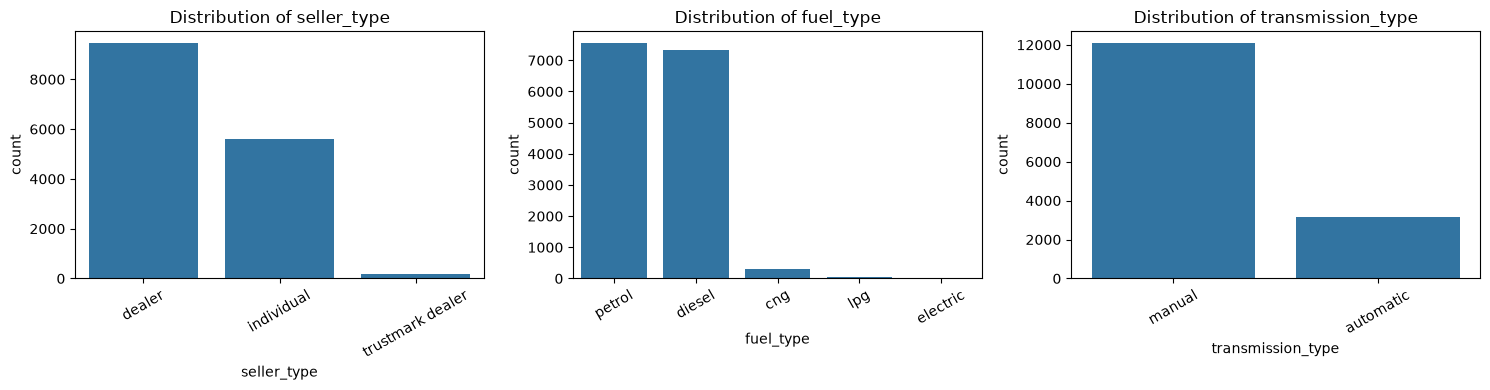

seller_type
dealer              9454
individual          5610
trustmark dealer     173
Name: count, dtype: int64

fuel_type
petrol      7553
diesel      7337
cng          299
lpg           44
electric       4
Name: count, dtype: int64

transmission_type
manual       12088
automatic     3149
Name: count, dtype: int64



In [22]:
fig, axes = make_grid(len(low_text_cardinality_cols), n_cols=3, cell_w=5, cell_h=4)
for i, c in enumerate(low_text_cardinality_cols):
    sns.countplot(data=X, x=c, order=X[c].value_counts().index, ax=axes[i])
    axes[i].set_title(f"Distribution of {c}")
    axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

for c in low_text_cardinality_cols:
    print(f"{X[c].value_counts()}\n")

Medium cardinality text columns

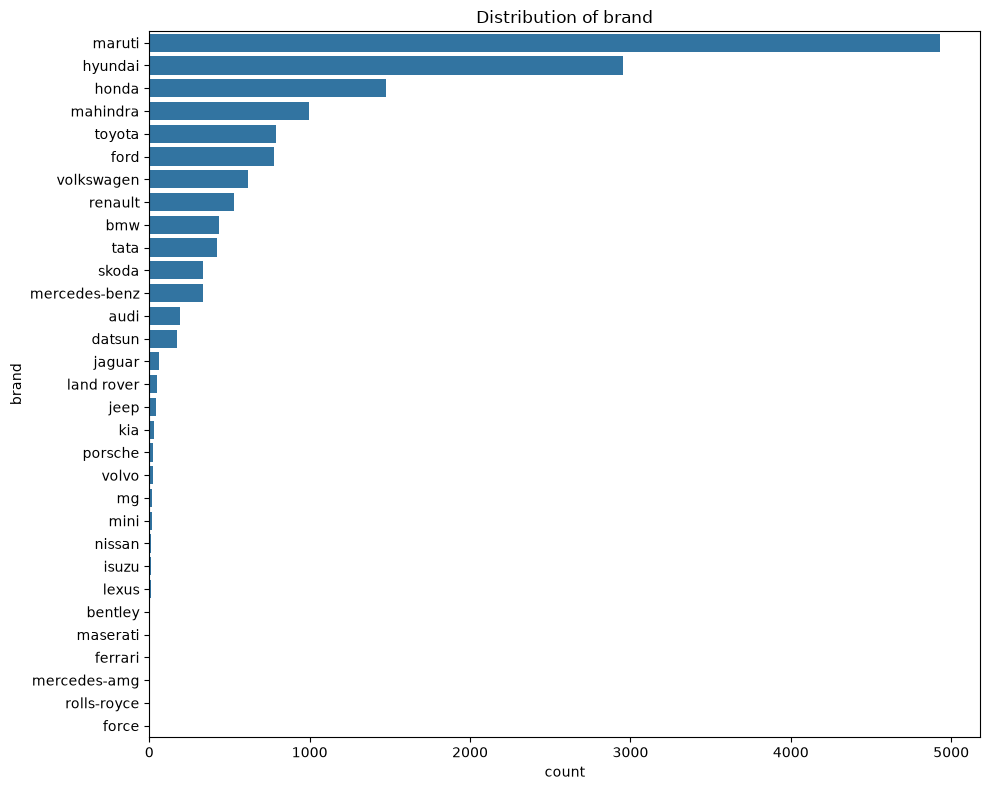

brand
maruti           4933
hyundai          2952
honda            1475
mahindra          998
toyota            787
ford              776
volkswagen        613
renault           526
bmw               436
tata              421
skoda             333
mercedes-benz     332
audi              190
datsun            170
jaguar             58
land rover         50
jeep               41
kia                32
porsche            21
volvo              20
mg                 19
mini               17
nissan             10
isuzu               9
lexus               9
bentley             3
maserati            2
ferrari             1
mercedes-amg        1
rolls-royce         1
force               1
Name: count, dtype: int64



In [23]:
fig, axes = make_grid(len(medium_text_cardinality_cols), n_cols=1, cell_w=10, cell_h=8)
for i, c in enumerate(medium_text_cardinality_cols):
    sns.countplot(data=X, y=c, order=X[c].value_counts().index, ax=axes[i])
    axes[i].set_title(f"Distribution of {c}")
plt.tight_layout()
plt.show()

for c in medium_text_cardinality_cols:
    print(f"{X[c].value_counts()}\n")

High cardinality text columns

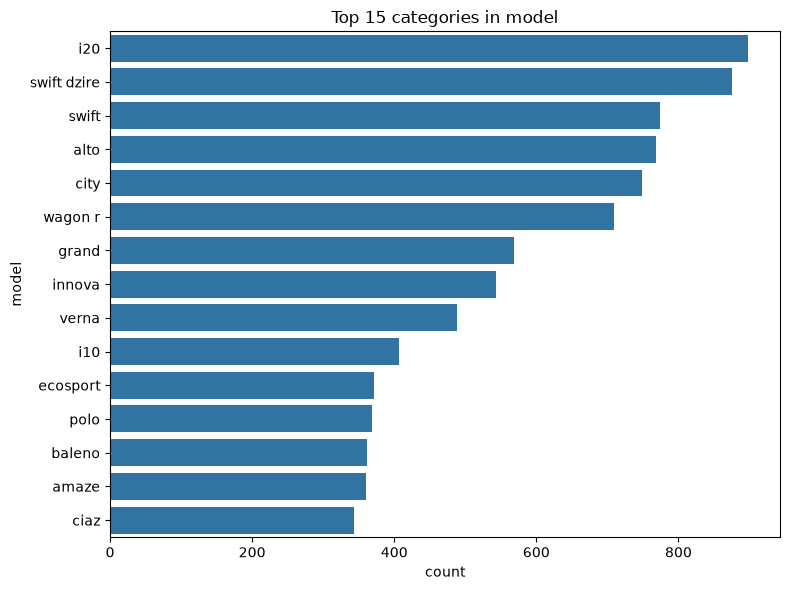

model: 120 unique values, top 15 cover 56% of rows


In [24]:
fig, axes = make_grid(len(high_text_cardinality_cols), n_cols=2, cell_w=8, cell_h=6)
for ax, c in zip(axes, high_text_cardinality_cols):
    top = X[c].value_counts().head(15).index
    sns.countplot(data=X, y=c, order=top, ax=ax)
    ax.set_title(f"Top 15 categories in {c}")
plt.tight_layout()
plt.show()

for c in high_text_cardinality_cols:
    print(f"{c}: {X[c].nunique()} unique values, top 15 cover {X[c].value_counts(normalize=True).head(15).sum():.0%} of rows")

Discrete numeric columns

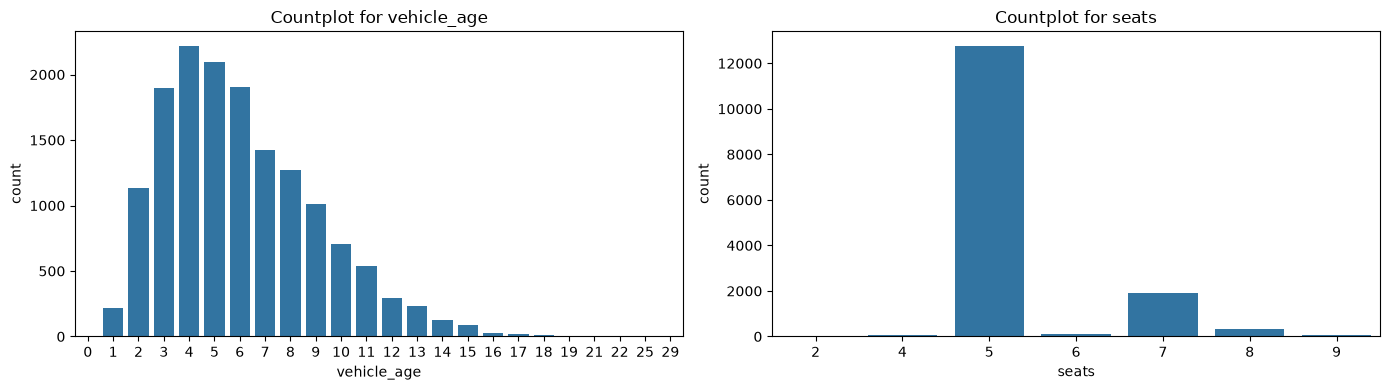

In [25]:
fig, axes = make_grid(len(discrete_cols), n_cols=2, cell_w=7, cell_h=4)
for i, c in  enumerate(discrete_cols):
    sns.countplot(data=X, x=c, ax=axes[i])
    axes[i].set_title(f"Countplot for {c}")
plt.tight_layout()
plt.show()

Continuous numeric columns

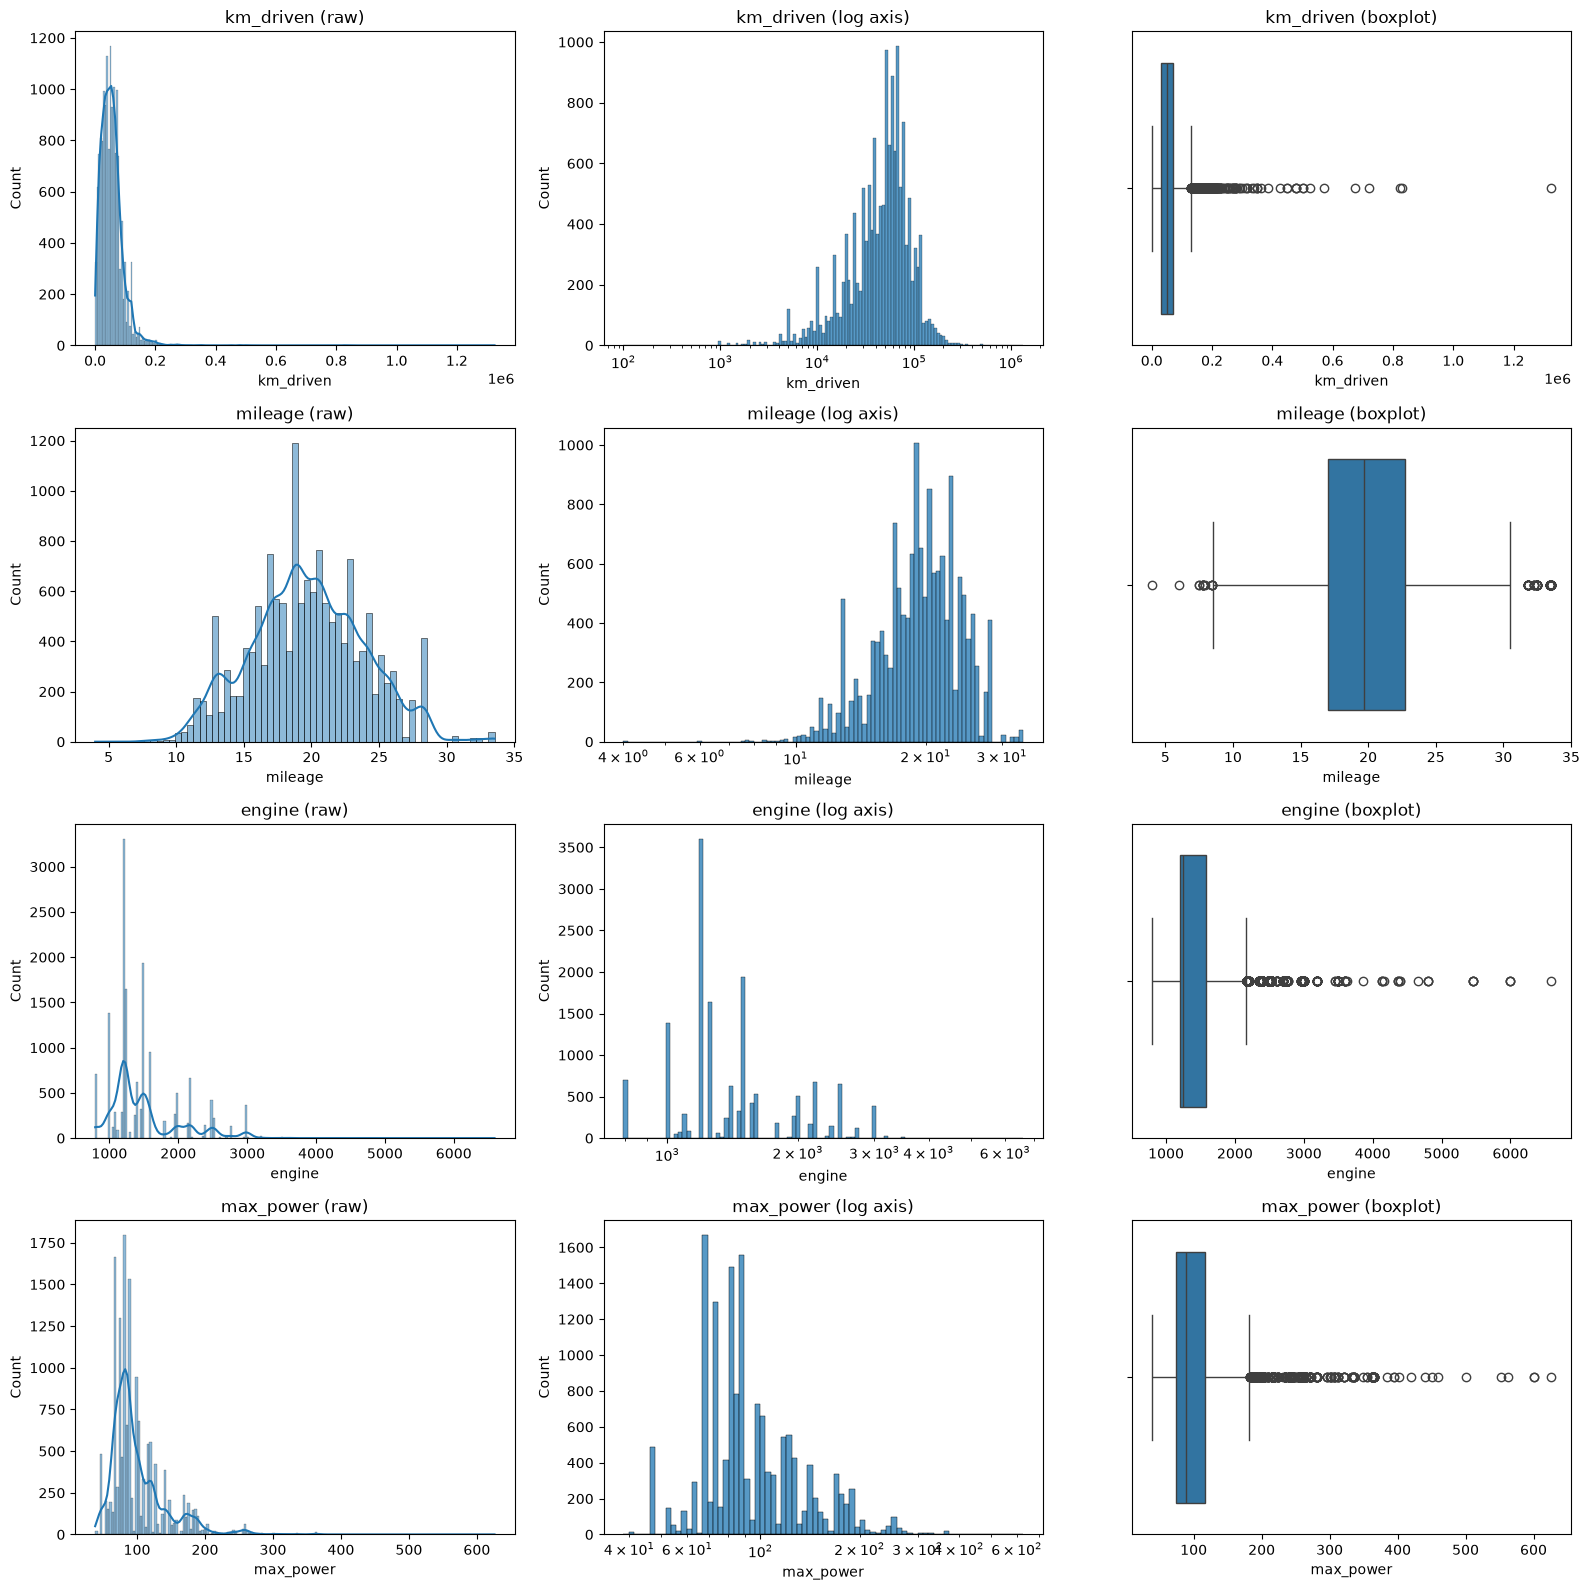

,skew
km_driven,5.49
mileage,0.11
engine,1.67
max_power,2.49


In [26]:
fig, axes = plt.subplots(len(continuous_cols), 3, figsize=(16, 4 * len(continuous_cols)), squeeze=False)
for i, c in enumerate(continuous_cols):
    sns.histplot(X[c], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{c} (raw)")
    sns.histplot(X[c], log_scale=True, ax=axes[i, 1])
    axes[i, 1].set_title(f"{c} (log axis)")
    sns.boxplot(x=X[c], ax=axes[i, 2])
    axes[i, 2].set_title(f"{c} (boxplot)")
plt.tight_layout()
plt.show()

display(X[continuous_cols].skew().round(2).rename("skew").to_frame())

Target: selling_price

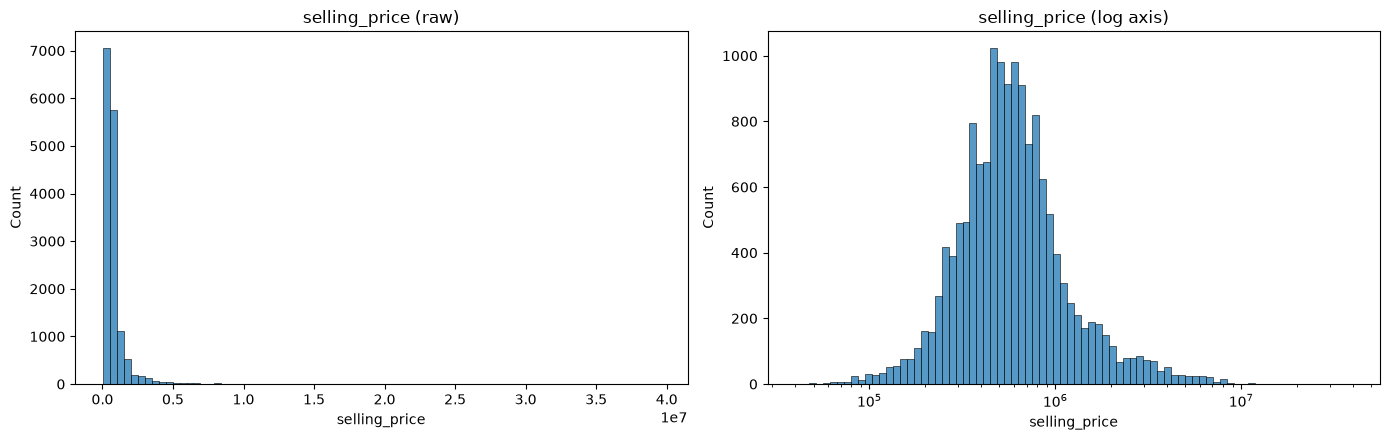

count       15237.0
mean       774543.0
std        894693.0
min         40000.0
25%        385000.0
50%        558000.0
75%        825000.0
99%       4532000.0
max      39500000.0
Name: selling_price, dtype: float64

skew raw: 10.11   skew of log1p: 0.57


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(target, bins=80, ax=ax[0])
ax[0].set_title("selling_price (raw)")
sns.histplot(target, bins=80, log_scale=True, ax=ax[1])
ax[1].set_title("selling_price (log axis)")
plt.tight_layout()
plt.show()

print(target.describe(percentiles=[.25, .5, .75, .99]).round(0))
print(f"\nskew raw: {target.skew():.2f}   skew of log1p: {np.log1p(target).skew():.2f}")

Finding -> Action

- Price is heavily right skewed; log1p makes it close to symmetric -> train on log1p(selling_price) and convert back with expm1 in predict.py
- km_driven, engine and max_power are right skewed -> log-transform or use tree models

BIVARIATE ANALYSIS

Continuous features vs price (log price axis, no line plot)

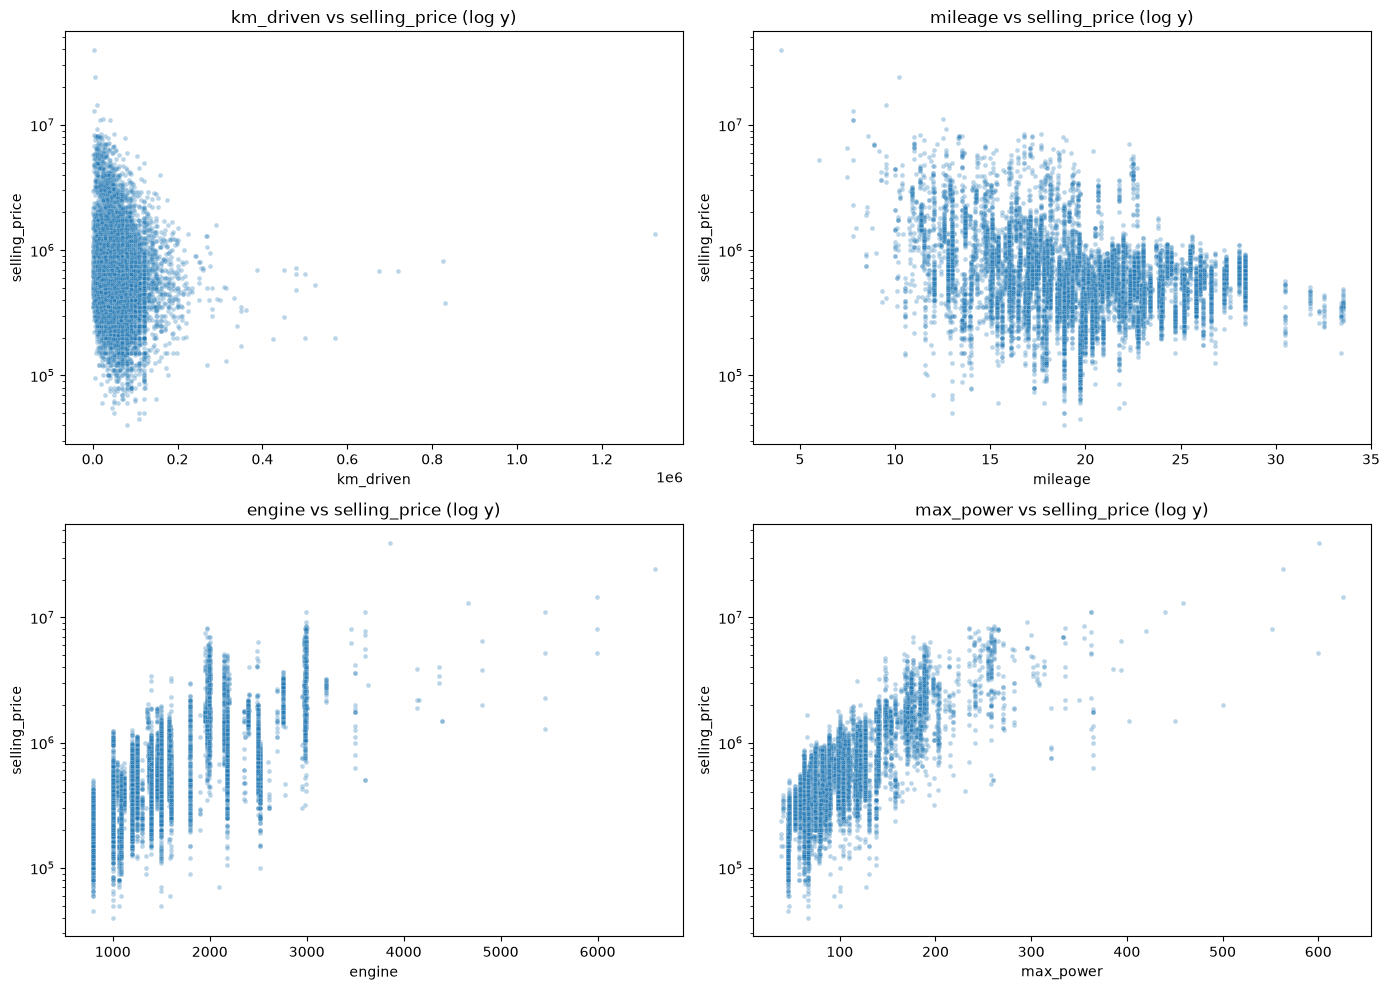

In [28]:
fig, axes = make_grid(len(continuous_cols), n_cols=2, cell_w=7, cell_h=5)
for i, c in enumerate(continuous_cols):
    sns.scatterplot(x=X[c], y=target, alpha=.3, s=12, ax=axes[i])
    axes[i].set_yscale("log")
    axes[i].set_title(f"{c} vs selling_price (log y)")
plt.tight_layout()
plt.show()

Median price by vehicle age (depreciation curve)

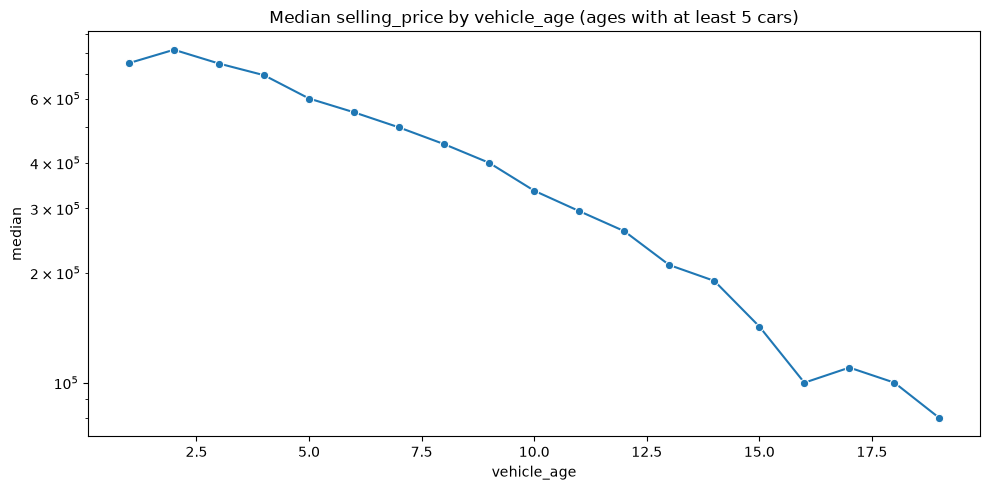

In [29]:
age_price = df_a.groupby("vehicle_age")["selling_price"].agg(["median", "count"])
age_price = age_price[age_price["count"] >= 5]

plt.figure(figsize=(10, 5))
sns.lineplot(x=age_price.index, y=age_price["median"], marker="o")
plt.yscale("log")
plt.title("Median selling_price by vehicle_age (ages with at least 5 cars)")
plt.tight_layout()
plt.show()

Vehicle age vs price, split by transmission

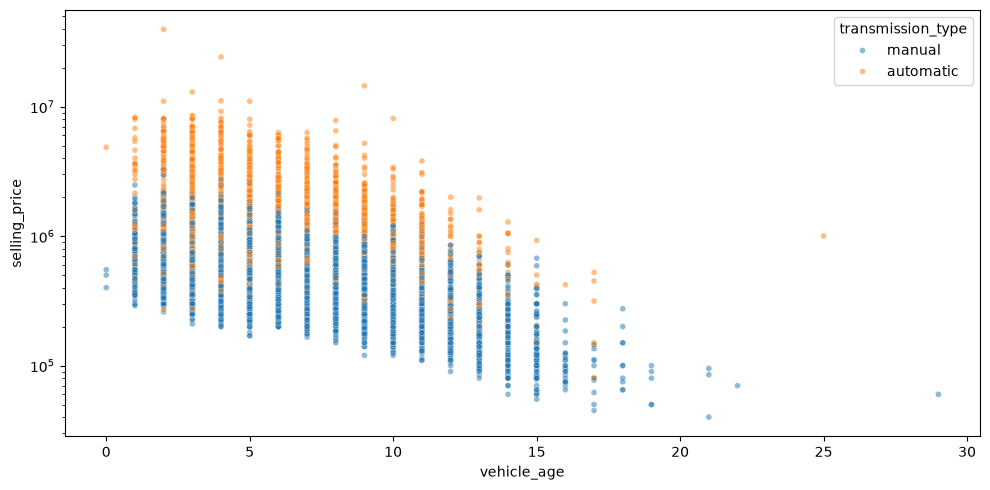

In [30]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_a, x="vehicle_age", y="selling_price", hue="transmission_type", alpha=.5, s=18)
plt.yscale("log")
plt.tight_layout()
plt.show()

Mileage vs price, split by fuel type

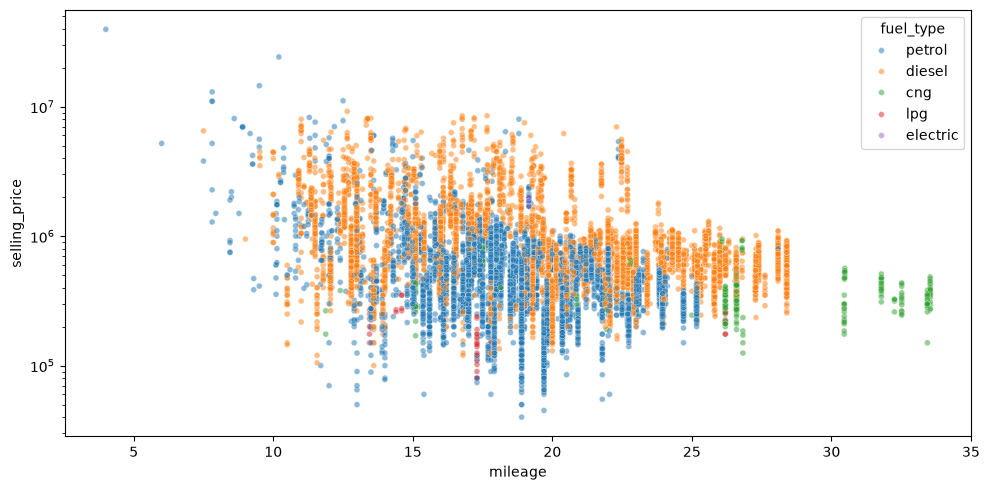

In [31]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_a, x="mileage", y="selling_price", hue="fuel_type", alpha=.5, s=18)
plt.yscale("log")
plt.tight_layout()
plt.show()

Price distribution inside each low-cardinality category (boxplot, log price)

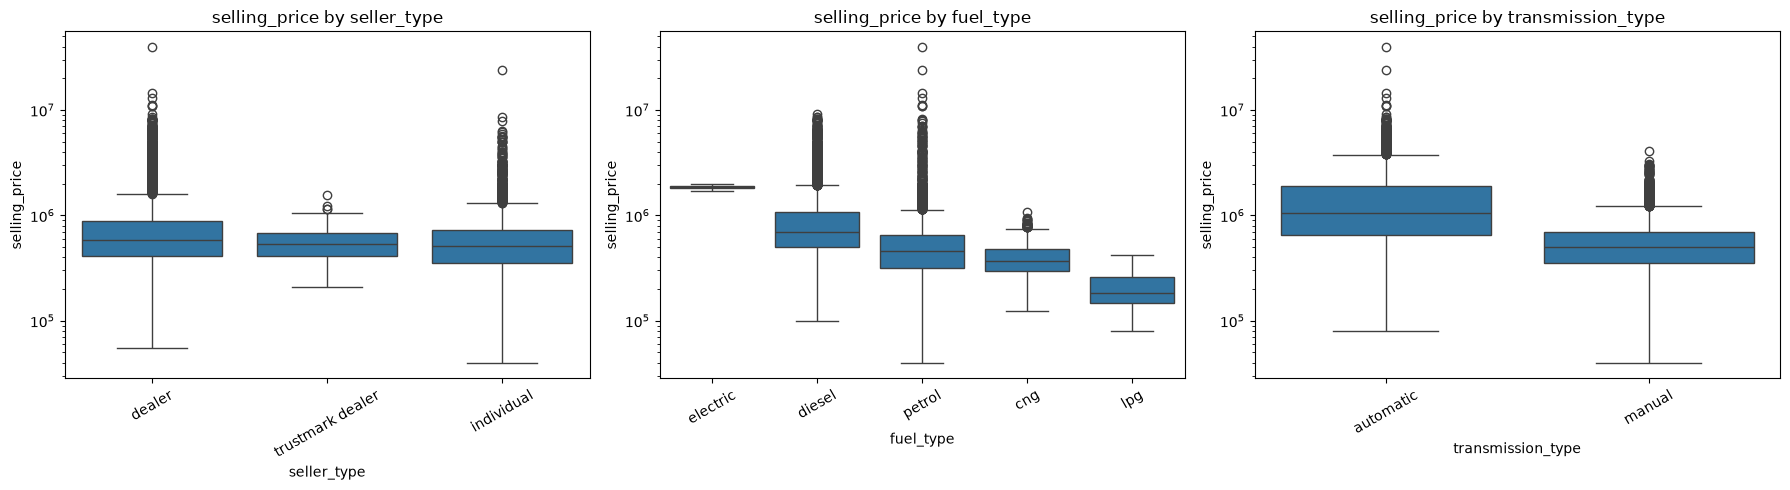

In [32]:
fig, axes = make_grid(len(low_text_cardinality_cols), n_cols=3, cell_w=6, cell_h=5)
for ax, c in zip(axes, low_text_cardinality_cols):
    order = df_a.groupby(c)["selling_price"].median().sort_values(ascending=False).index
    sns.boxplot(data=df_a, x=c, y="selling_price", order=order, ax=ax)
    ax.set_yscale("log")
    ax.set_title(f"selling_price by {c}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Price by brand (median, with number of cars)

,median_price,cars
brand,,
ferrari,39500000.0,1
rolls-royce,24200000.0,1
bentley,8100000.0,3
maserati,6100000.0,2
mercedes-amg,5100000.0,1
porsche,5000000.0,21
lexus,4700000.0,9
volvo,3750000.0,20
land rover,3487500.0,50


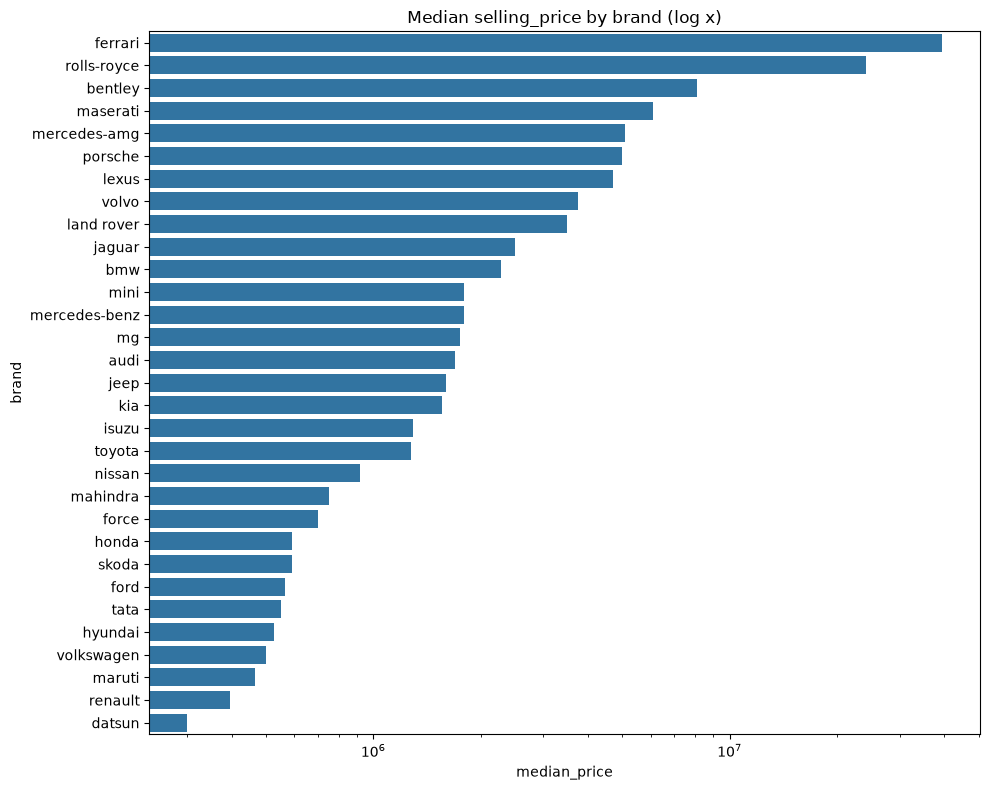

In [33]:
brand_stats = (df_a.groupby("brand")["selling_price"]
               .agg(median_price="median", cars="count")
               .sort_values("median_price", ascending=False))
display(brand_stats)

plt.figure(figsize=(10, 8))
sns.barplot(x=brand_stats["median_price"], y=brand_stats.index)
plt.xscale("log")
plt.title("Median selling_price by brand (log x)")
plt.tight_layout()
plt.show()

Price by discrete columns (vehicle_age, seats)

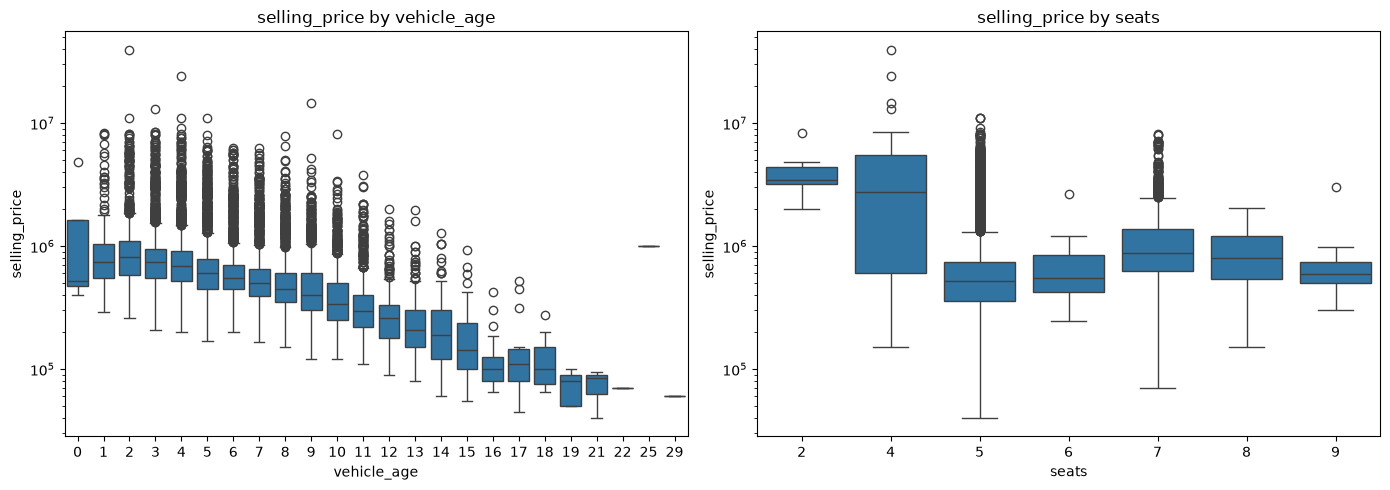

In [34]:
fig, axes = make_grid(len(discrete_cols), n_cols=2, cell_w=7, cell_h=5)
for i,c in enumerate(discrete_cols):
    sns.boxplot(data=df_a, x=c, y="selling_price", ax=axes[i])
    axes[i].set_yscale("log")
    axes[i].set_title(f"selling_price by {c}")
plt.tight_layout()
plt.show()

CORRELATION

Spearman is used because price, km_driven, engine and max_power are skewed and the relationships are not perfectly linear. `log_price` is added so the target is on the scale we will actually model.

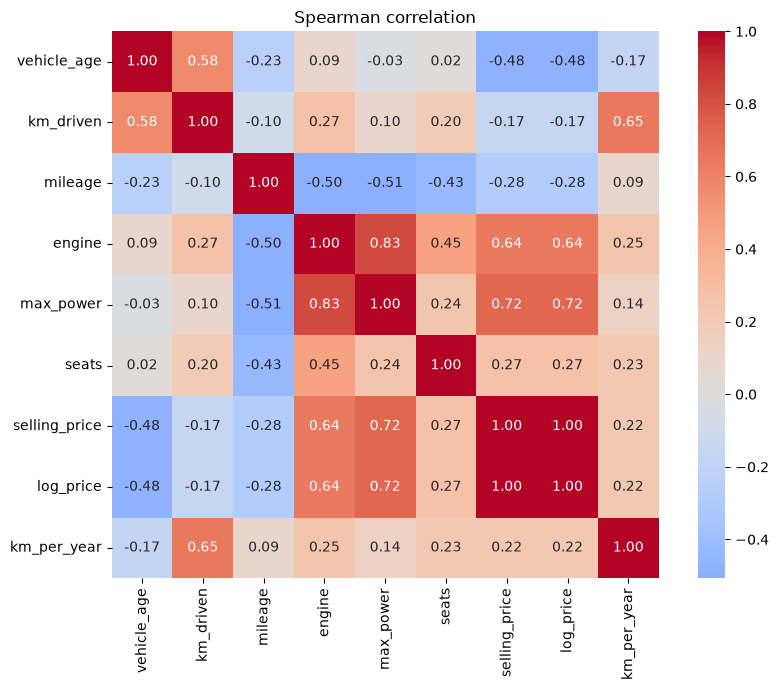

,corr with log_price
max_power,0.72
engine,0.64
vehicle_age,-0.48
mileage,-0.28
seats,0.27
km_per_year,0.22
km_driven,-0.17


In [35]:
corr_df = df_a[numeric_cols + ["selling_price"]].copy()
corr_df["log_price"] = np.log1p(corr_df["selling_price"])
corr_df["km_per_year"] = df_a["km_driven"] / df_a["vehicle_age"].clip(lower=1)

corr = corr_df.corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Spearman correlation")
plt.tight_layout()
plt.show()

display(corr["log_price"].drop(["log_price", "selling_price"]).sort_values(key=abs, ascending=False).round(2).to_frame("corr with log_price"))

Collinearity between features

In [36]:
print("engine vs max_power  :", round(df_a["engine"].corr(df_a["max_power"], method="spearman"), 2))
print("engine vs mileage    :", round(df_a["engine"].corr(df_a["mileage"], method="spearman"), 2))
print("max_power vs mileage :", round(df_a["max_power"].corr(df_a["mileage"], method="spearman"), 2))

engine vs max_power  : 0.83
engine vs mileage    : -0.5
max_power vs mileage : -0.51


WHAT data_cleaning.py WILL DO

Drop `Unnamed*` index columns  
Strip + lowercase all text columns (merges `Isuzu` / `ISUZU`)  
Drop `car_name` (derivable from brand + model)  
Handle missing values (none in this file, but must be handled for new data)  
Drop exact duplicate rows (after step 2, price included)  
Drop impossible values (seats/engine/max_power/mileage/selling_price <= 0)  
Drop impossible/ outlier values of km per year  
Do NOT remove genuine luxury cars just because IQR flags them  

WHAT features.py SHOULD DO

km_per_year, log_km_driven, power per cc, is_luxury, is_automatic, brand_model  
log1p(selling_price) as the training target  

WHAT train.py SHOULD DO  
 
Scaling, encoding , fitted on the train split only  